# SCAM SMS DETECTION WITH NLP




## 1 Import Modules and Load Dataset

In [ ]:
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required resources
nltk.download('stopwords')
nltk.download('wordnet')

# Load dataset
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df = pd.read_csv(url, sep='\t', header=None, names=['label', 'message'])
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

## 2 Preprocessing Text

Clean unstructured messages by converting all characters to lowercase, filtering out non-alphabetic characters, removing English stop-words, and applying lemmatization to compress vocabulary.


In [8]:
# Preprocessing function
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = ''.join([c.lower() for c in text if c.isalpha() or c == ' '])
    words = text.split()
    return ' '.join([lemmatizer.lemmatize(w) for w in words if w not in stop_words])

df['clean_message'] = df['message'].apply(clean_text)

## 3. Extract Features using TF-IDF:Step 
Converting cleaned string data into numerical feature matrices using Term Frequency-Inverse Document Frequency (TF-IDF), keeping the top 3,000 most significant words.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=3000)
X = vectorizer.fit_transform(df['clean_message'])
y = df['label_num']

## 4.Split Data into Train & Test Sets

Dividing the vector matrices into training (80%) and testing (20%) sets using stratified sampling to preserve the target class imbalance ratio.

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

## 5.Train Multinomial Naive Bayes Model

Instantiate and fit the MultinomialNB classifier on the transformed training matrices.

In [17]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()
model.fit(X_train, y_train)

MultinomialNB()

## 6.Evaluate & Plot Metrics
Generate predictions on unseen test data, output precision and recall classification metrics, and display a formatted confusion matrix heatmap.

              precision    recall  f1-score   support

         Ham       0.97      1.00      0.99       966
        Spam       0.99      0.81      0.89       149

    accuracy                           0.97      1115
   macro avg       0.98      0.91      0.94      1115
weighted avg       0.97      0.97      0.97      1115



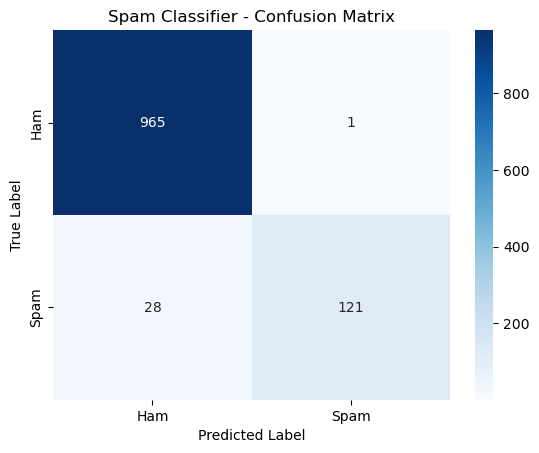

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred, target_names=['Ham', 'Spam']))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Spam Classifier - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

## 7. Running Live Predictions on Custom SMS 

 Created a Python helper function designed to take raw text strings, process them through the fitted vectorizer and model, and display the prediction alongside its probability confidence score.

In [28]:
def predict_sms(custom_message, model, vectorizer):
  """Cleans input text, transforms it using the fitted vectorizer, and prints the predicted class and confidence score.

  """
  # 1. Clean raw text using the preprocessing step
  cleaned_text = clean_text(custom_message)

  # 2. Vectorize the cleaned string (must pass list format)
  vectorized_text = vectorizer.transform([cleaned_text])

  # 3. Predict class label and class probabilities
  prediction = model.predict(vectorized_text)[0]
  probabilities = model.predict_proba(vectorized_text)[0]

  # 4. Extract class details
  label = 'SPAM' if prediction == 1 else 'HAM (Legitimate)'
  confidence = probabilities[prediction] * 100

  # Print formatted result
  print(f"Message:    '{custom_message}'")
  print(f'Prediction: {label}')
  print(f'Confidence: {confidence:.2f}%\n')


# --- Example Test Cases ---

# Test 1: High-probability Spam
predict_sms(
    'CONGRATULATIONS! You have won a $1,000 Walmart gift card. Go to'
    ' http://claim-now.com to claim before it expires!',
    model,
    vectorizer,
)

# Test 2: Standard Ham (Legitimate) message
predict_sms(
    'Hey, let me know when you arrive at the library so I can open the door.',
    model,
    vectorizer,
)

# Test 3: Ambiguous or tricky input
predict_sms(
    'Free tomorrow afternoon? Want to grab some coffee and work on our NLP'
    ' project?',
    model,
    vectorizer,
)

Message:    'CONGRATULATIONS! You have won a $1,000 Walmart gift card. Go to http://claim-now.com to claim before it expires!'
Prediction: SPAM
Confidence: 79.10%

Message:    'Hey, let me know when you arrive at the library so I can open the door.'
Prediction: HAM (Legitimate)
Confidence: 95.85%

Message:    'Free tomorrow afternoon? Want to grab some coffee and work on our NLP project?'
Prediction: HAM (Legitimate)
Confidence: 98.30%



# Making An Interactive Dashboard With Streamlit 

## 1. dumping trained model and pipeline to folder directory

In [33]:
import joblib

# Saving model and TF-IDF vectorizer to disk
joblib.dump(model, 'spam_model.pkl')
joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')

print("Model saved successfully!")

Model saved successfully!
